# Infer Manning roughness from uniform flow, then predict a subcritical backwater.

Run in a Python environment with OneSimulation 0.2.0, NumPy, SciPy and Matplotlib. Change the input data and rerun to compare with the saved reference output.

fitted Manning n = 0.03001 s/m^(1/3)
outlet 1.8 m: depth 1 km upstream = 1.605 m
outlet 2.2 m: depth 1 km upstream = 1.745 m


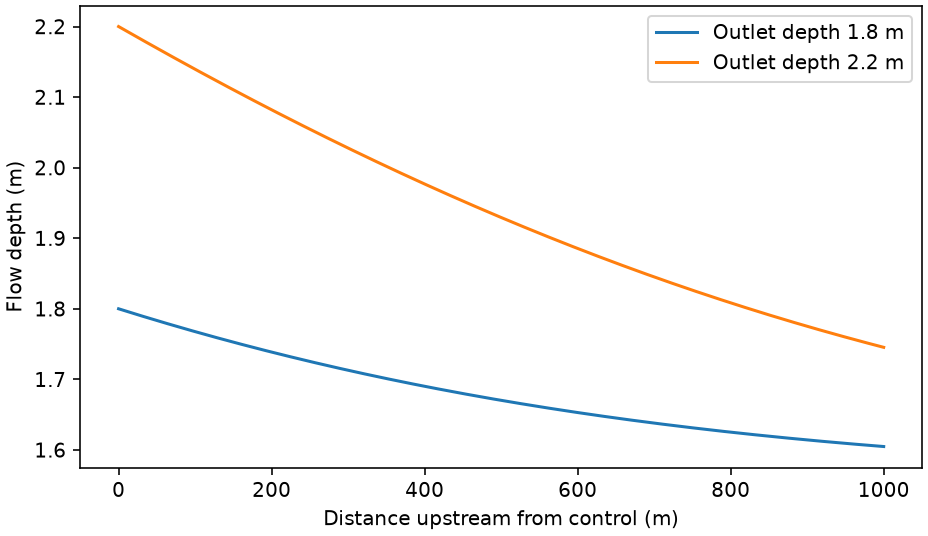

In [1]:
"""Infer Manning roughness from uniform flow, then predict a subcritical backwater."""
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from onesim.numerics.nonlinear import LeastSquares

width, slope, discharge, gravity = 4.0, 0.001, 6.0, 9.81
measured_depth = np.array([0.7,0.85,1.0,1.15])  # m
def section(depth):
    area = width*depth
    return area, area/(width+2*depth)
def uniform(depth, roughness):
    area, radius = section(depth)
    return area*radius**(2/3)*np.sqrt(slope)/roughness
measured_flow = uniform(measured_depth,0.030) + np.array([0.02,-0.03,0.02,-0.01])
fit = LeastSquares().solve(lambda n: uniform(measured_depth,n[0])-measured_flow,
                           [0.025], bounds=([0.010],[0.08]))
roughness = fit.x[0]
def depth_gradient(x, y):
    area,radius = section(y)
    friction = (roughness*discharge/(area*radius**(2/3)))**2
    froude_squared = discharge**2*width/(gravity*area**3)
    return (slope-friction)/(1-froude_squared)

fig, ax = plt.subplots(figsize=(6.4,3.7), layout="constrained")
print(f"fitted Manning n = {roughness:.5f} s/m^(1/3)")
for boundary in [1.8, 2.2]:
    x = np.linspace(0,-1000,250)
    sol = solve_ivp(depth_gradient,[0,-1000],[boundary],t_eval=x,rtol=1e-9,atol=1e-10)
    assert sol.success
    print(f"outlet {boundary:.1f} m: depth 1 km upstream = {sol.y[0,-1]:.3f} m")
    ax.plot(-sol.t,sol.y[0],label=f"Outlet depth {boundary:.1f} m")
ax.set(xlabel="Distance upstream from control (m)",ylabel="Flow depth (m)")
ax.legend()
plt.show()
